# Week 3: Statistical Analysis and Hypothesis Testing
## Titanic passenger sex and survival

This notebook downloads the public Titanic CSV and tests whether passenger sex and survival outcome are associated.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, fisher_exact
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Hypotheses
- H0: Sex and survival are independent.
- H1: Sex and survival are associated.
- Significance level: 0.05.

In [2]:
data = df[["Sex", "Survived"]].dropna()
observed = pd.crosstab(data["Sex"], data["Survived"]).reindex(index=["female","male"], columns=[1,0])
observed.columns = ["Survived", "Did not survive"]
display(observed)
display(data.groupby("Sex")["Survived"].agg(["count","sum","mean"]))


,Survived,Did not survive
Sex,,
female,233,81
male,109,468


,count,sum,mean
Sex,,,
female,314,233,0.742038
male,577,109,0.188908


## Chi-square test, effect size, and Fisher exact check

In [3]:
chi2, p_value, dof, expected = chi2_contingency(observed, correction=False)
n = observed.to_numpy().sum()
print(f"chi2={chi2:.4f}, df={dof}, p={p_value:.6g}")
print("Expected counts:")
display(pd.DataFrame(expected,index=observed.index,columns=observed.columns))
print("Cramer's V:", np.sqrt(chi2/n))
print("Fisher exact:", fisher_exact(observed.to_numpy()))


chi2=263.0506, df=1, p=3.71175e-59
Expected counts:


,Survived,Did not survive
Sex,,
female,120.525253,193.474747
male,221.474747,355.525253


Cramer's V: 0.5433513806577551
Fisher exact: SignificanceResult(statistic=np.float64(12.3506625891947), pvalue=np.float64(6.463921564583144e-60))


## Visualizations

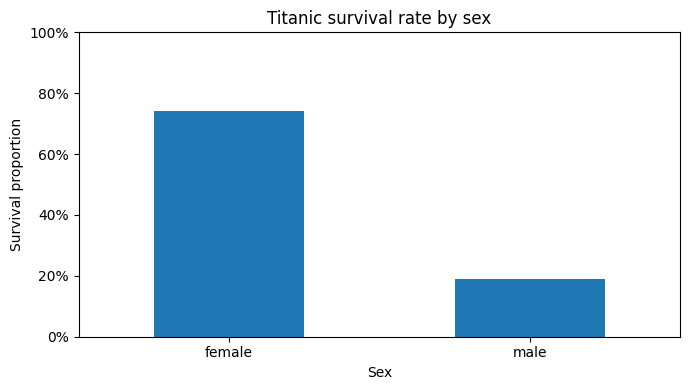

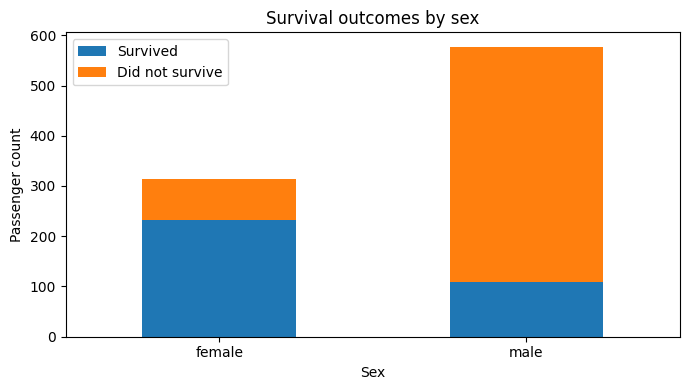

In [4]:
rates = data.groupby("Sex")["Survived"].mean().reindex(["female","male"])
ax = rates.plot(kind="bar", ylim=(0,1), figsize=(7,4), rot=0)
ax.set_ylabel("Survival proportion")
ax.set_title("Titanic survival rate by sex")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout(); plt.show()

observed.plot(kind="bar", stacked=True, figsize=(7,4), rot=0,
              title="Survival outcomes by sex", ylabel="Passenger count")
plt.tight_layout(); plt.show()


## Confidence interval and interpretation

In [5]:
female = data[data["Sex"]=="female"]["Survived"]
male = data[data["Sex"]=="male"]["Survived"]
pf, pm = female.mean(), male.mean()
difference = pf-pm
se = np.sqrt(pf*(1-pf)/len(female) + pm*(1-pm)/len(male))
print("Female survival:", pf)
print("Male survival:", pm)
print("Difference:", difference)
print("Approx. 95% CI:", (difference-1.96*se, difference+1.96*se))
print("Decision:", "Reject H0" if p_value < 0.05 else "Do not reject H0")


Female survival: 0.7420382165605095
Male survival: 0.18890814558058924
Difference: 0.5531300709799203
Approx. 95% CI: (np.float64(0.49514722081888213), np.float64(0.6111129211409585))
Decision: Reject H0
